Upload student_performance_dataset.csv or .xlsx


Saving student_performance_dataset.csv to student_performance_dataset (2).csv

EXPERIMENT 1: PREPROCESSING
Dataset Shape: (1000, 7)
   StudyHours  Attendance  AssignmentMarks  PreviousMarks  SleepHours  \
0        3.75       51.11            48.32          73.82        7.00   
1        9.51       72.51            47.29          83.73        8.64   
2        7.32       92.38            93.44          40.04        8.32   
3        5.99       83.93            47.47          69.99        4.08   
4        1.56       88.39            49.04          65.74        4.04   

   FinalScore Performance  
0       51.15     Average  
1       58.13     Average  
2       71.06     Average  
3       69.18     Average  
4       57.81     Average  

Missing Values:
 StudyHours         0
Attendance         0
AssignmentMarks    0
PreviousMarks      0
SleepHours         0
FinalScore         0
Performance        0
dtype: int64

Class Distribution:
 Performance
Average    689
Low        191
High       120
Name

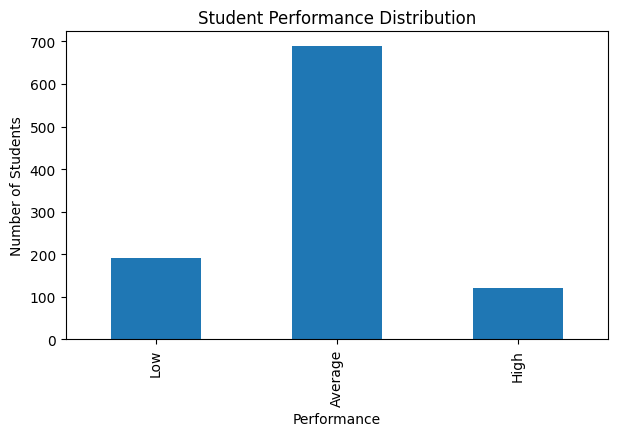

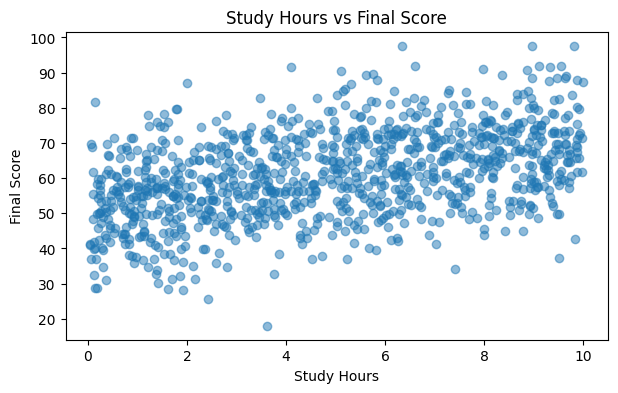


EXPERIMENT 2: BINARY AND MULTICLASS CLASSIFICATION
Binary SVM Accuracy: 90.5 %
Binary Random Forest Accuracy: 90.0 %

EXPERIMENT 3: DECISION TREE
Decision Tree Accuracy: 71.5 %
              precision    recall  f1-score   support

     Average       0.77      0.85      0.81       138
        High       0.48      0.46      0.47        24
         Low       0.58      0.39      0.47        38

    accuracy                           0.71       200
   macro avg       0.61      0.57      0.58       200
weighted avg       0.70      0.71      0.70       200



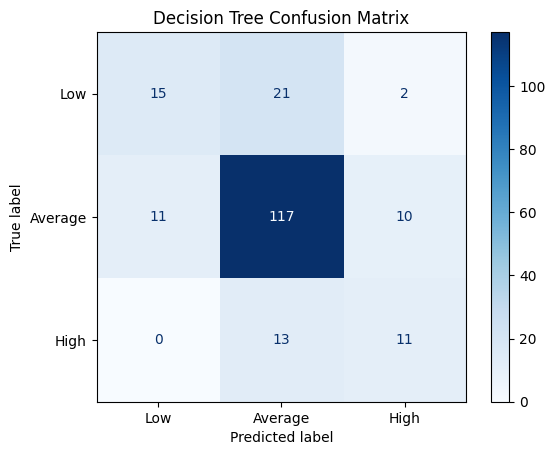

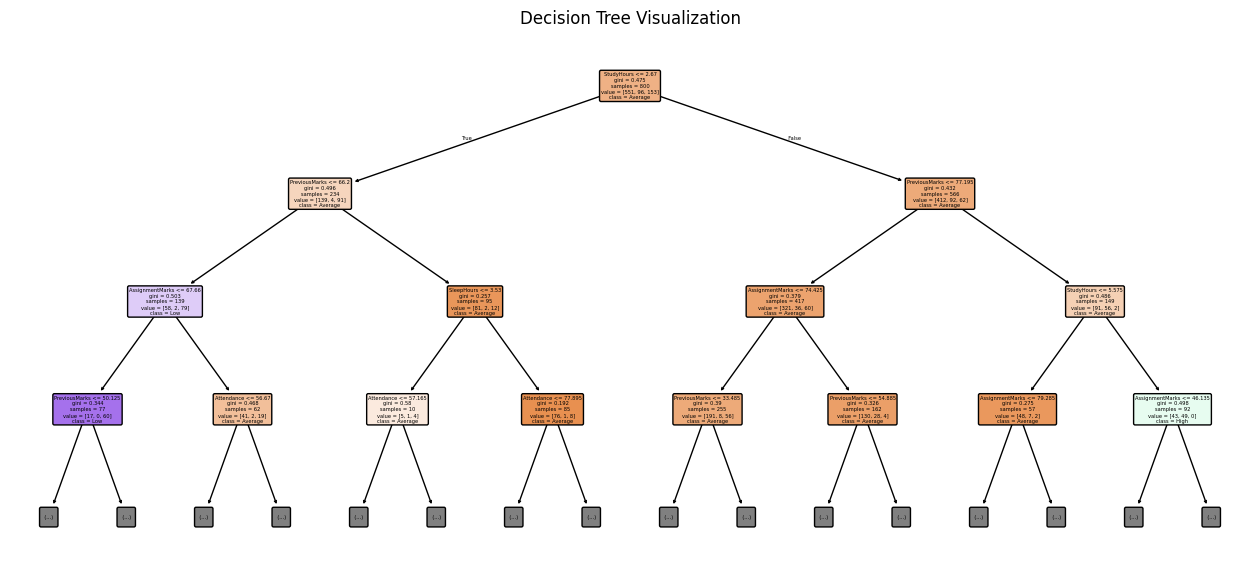


EXPERIMENT 4A AND 4B: SVM AND RANDOM FOREST
SVM Accuracy: 76.0 %
Random Forest Accuracy: 76.0 %
Decision Tree Accuracy: 71.5 %


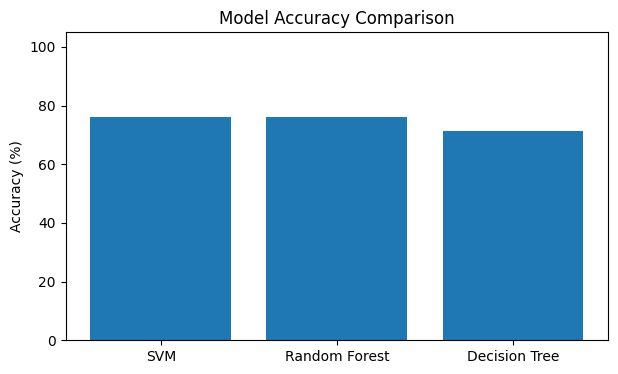

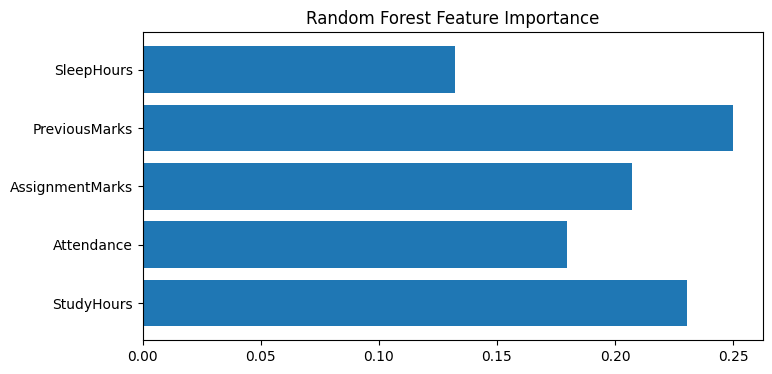


EXPERIMENT 5: K-MEANS AND PCA


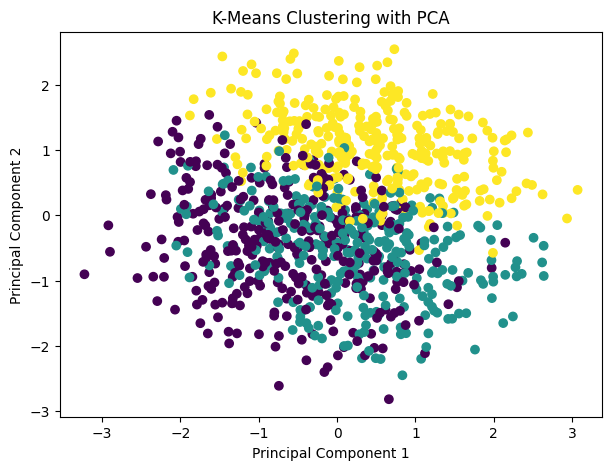

Cluster Counts: [356 326 318]
PCA Variance Explained: 42.2 %

EXPERIMENT 6: FEEDFORWARD AND CONVOLUTIONAL NEURAL NETWORKS
FNN Accuracy: 76.5 %
CNN Accuracy: 73.5 %


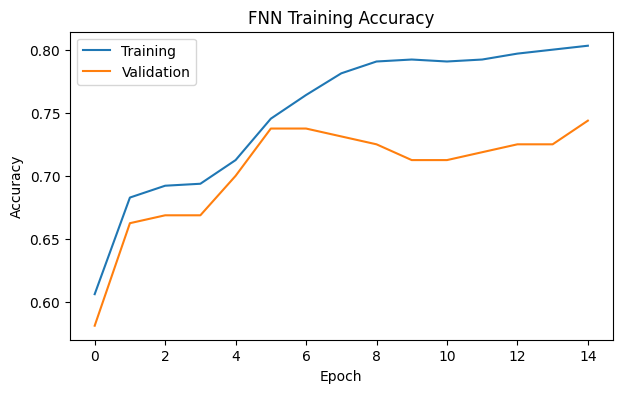

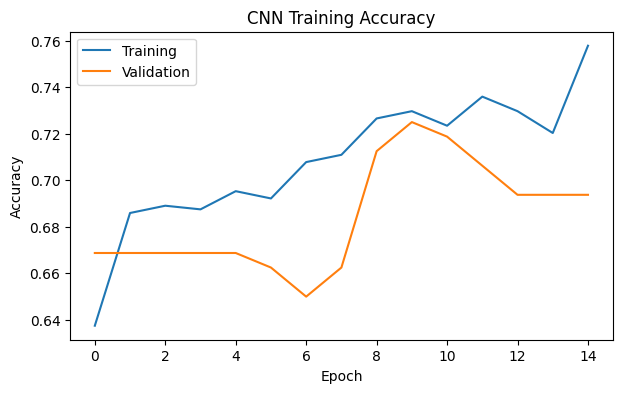


EXPERIMENT 7: GENERATIVE ADVERSARIAL NETWORK
Synthetic Student Records:
   StudyHours  Attendance  AssignmentMarks  PreviousMarks  SleepHours
0        5.51   78.660004        61.930000      68.529999        6.75
1        6.14   91.779999        58.910000      81.209999        6.01
2        5.68   84.419998        63.040001      69.139999        5.99
3        5.40   85.330002        62.080002      71.080002        6.03
4        5.77   92.989998        60.630001      81.459999        5.23


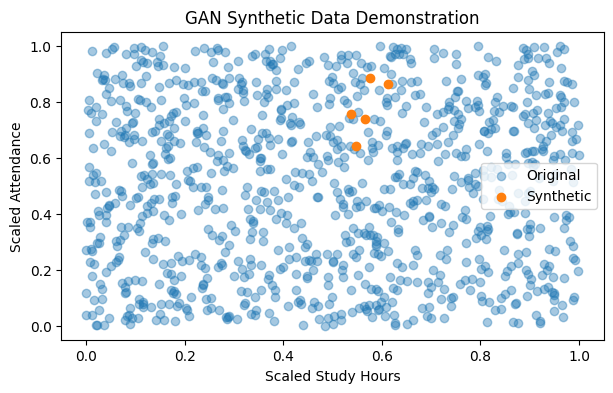


EXPERIMENT 8: GRID SEARCH AND CROSS-VALIDATION
Best Parameters: {'svc__C': 10, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Cross-Validation Accuracy: 79.38 %
Test Accuracy: 78.0 %


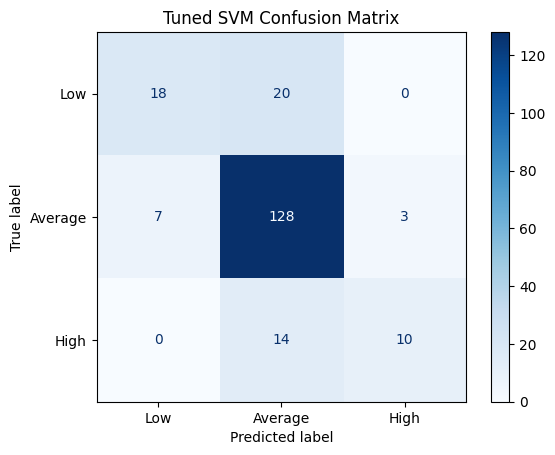


EXPERIMENT 9: FLASK REST API AND DOCKER


INFO:werkzeug:127.0.0.1 - - [13/Oct/2026 11:02:44] "GET / HTTP/1.1" 200 -
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
INFO:werkzeug:127.0.0.1 - - [13/Oct/2026 11:02:44] "POST /predict HTTP/1.1" 200 -


API Home: {'message': 'Student Performance API is running'}
Sample Features: [5.43, 84.25, 85.04, 41.39, 3.72]
Prediction: {'predicted_performance': 'Average'}
HTTP Status: 200

Created Files:
student_performance_output.csv True
student_model.pkl True
app.py True
requirements.txt True
Dockerfile True

Docker commands for a Docker-enabled computer:
docker build -t student-performance .
docker run -p 5000:5000 student-performance
Download the output files from the Colab Files panel.


In [2]:

!pip install flask scikit-learn joblib requests pandas matplotlib openpyxl tensorflow -q

import os, time, socket, threading
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import requests

from google.colab import files
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from flask import Flask, request, jsonify
from werkzeug.serving import make_server

print("Upload student_performance_dataset.csv or .xlsx")
uploaded = files.upload()
filename = next(iter(uploaded))

if filename.lower().endswith(".csv"):
    df = pd.read_csv(filename)
else:
    df = pd.read_excel(filename)

features = [
    "StudyHours", "Attendance", "AssignmentMarks",
    "PreviousMarks", "SleepHours"
]

X = df[features]
y = df["Performance"]

class_names = ["Low", "Average", "High"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\nEXPERIMENT 1: PREPROCESSING")
print("Dataset Shape:", df.shape)
print(df.head())
print("\nMissing Values:\n", df.isnull().sum())
print("\nClass Distribution:\n", y.value_counts())

plt.figure(figsize=(7, 4))
y.value_counts().reindex(class_names).plot(kind="bar")
plt.title("Student Performance Distribution")
plt.xlabel("Performance")
plt.ylabel("Number of Students")
plt.show()

plt.figure(figsize=(7, 4))
plt.scatter(df["StudyHours"], df["FinalScore"], alpha=0.5)
plt.xlabel("Study Hours")
plt.ylabel("Final Score")
plt.title("Study Hours vs Final Score")
plt.show()

print("\nEXPERIMENT 2: BINARY AND MULTICLASS CLASSIFICATION")

yb = (y == "High").astype(int)
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X, yb, test_size=0.2, random_state=42, stratify=yb
)

binary_svm = make_pipeline(StandardScaler(), SVC())
binary_svm.fit(Xb_train, yb_train)

binary_rf = RandomForestClassifier(n_estimators=100, random_state=42)
binary_rf.fit(Xb_train, yb_train)

print("Binary SVM Accuracy:",
      round(accuracy_score(yb_test, binary_svm.predict(Xb_test))*100, 2), "%")
print("Binary Random Forest Accuracy:",
      round(accuracy_score(yb_test, binary_rf.predict(Xb_test))*100, 2), "%")

print("\nEXPERIMENT 3: DECISION TREE")

dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

print("Decision Tree Accuracy:",
      round(accuracy_score(y_test, dt_pred)*100, 2), "%")
print(classification_report(y_test, dt_pred, zero_division=0))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, dt_pred, labels=class_names),
    display_labels=class_names
).plot(cmap="Blues")
plt.title("Decision Tree Confusion Matrix")
plt.show()

plt.figure(figsize=(16, 7))
plot_tree(dt_model, feature_names=features,
          class_names=dt_model.classes_, filled=True,
          rounded=True, max_depth=3)
plt.title("Decision Tree Visualization")
plt.show()

print("\nEXPERIMENT 4A AND 4B: SVM AND RANDOM FOREST")

svm_model = make_pipeline(StandardScaler(), SVC())
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

models = {
    "SVM": svm_model,
    "Random Forest": rf_model,
    "Decision Tree": dt_model
}

scores = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    scores[name] = accuracy_score(y_test, pred)
    print(name, "Accuracy:", round(scores[name]*100, 2), "%")

plt.figure(figsize=(7, 4))
plt.bar(scores.keys(), [v*100 for v in scores.values()])
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")
plt.ylim(0, 105)
plt.show()

plt.figure(figsize=(8, 4))
plt.barh(features, rf_model.feature_importances_)
plt.title("Random Forest Feature Importance")
plt.show()

print("\nEXPERIMENT 5: K-MEANS AND PCA")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap="viridis")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering with PCA")
plt.show()

print("Cluster Counts:", np.bincount(clusters))
print("PCA Variance Explained:",
      round(sum(pca.explained_variance_ratio_)*100, 2), "%")

print("\nEXPERIMENT 6: FEEDFORWARD AND CONVOLUTIONAL NEURAL NETWORKS")

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Conv1D, Flatten, MaxPooling1D, Dropout
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(42)

label_map = {"Low": 0, "Average": 1, "High": 2}
ytr_num = y_train.map(label_map).to_numpy()
yte_num = y_test.map(label_map).to_numpy()

nn_scaler = StandardScaler()
Xtr = nn_scaler.fit_transform(X_train)
Xte = nn_scaler.transform(X_test)

ytr = to_categorical(ytr_num, 3)
yte = to_categorical(yte_num, 3)

fnn = Sequential([
    Input(shape=(len(features),)),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(3, activation="softmax")
])

fnn.compile(optimizer="adam",
            loss="categorical_crossentropy", metrics=["accuracy"])

fnn_history = fnn.fit(
    Xtr, ytr, epochs=15, batch_size=32,
    validation_split=0.2, verbose=0
)

_, fnn_acc = fnn.evaluate(Xte, yte, verbose=0)
print("FNN Accuracy:", round(fnn_acc*100, 2), "%")

cnn = Sequential([
    Input(shape=(len(features), 1)),
    Conv1D(16, 2, activation="relu", padding="same"),
    MaxPooling1D(2),
    Flatten(),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(3, activation="softmax")
])

cnn.compile(optimizer="adam",
            loss="categorical_crossentropy", metrics=["accuracy"])

cnn_history = cnn.fit(
    Xtr[..., np.newaxis], ytr, epochs=15,
    batch_size=32, validation_split=0.2, verbose=0
)

_, cnn_acc = cnn.evaluate(Xte[..., np.newaxis], yte, verbose=0)
print("CNN Accuracy:", round(cnn_acc*100, 2), "%")

plt.figure(figsize=(7, 4))
plt.plot(fnn_history.history["accuracy"], label="Training")
plt.plot(fnn_history.history["val_accuracy"], label="Validation")
plt.title("FNN Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(cnn_history.history["accuracy"], label="Training")
plt.plot(cnn_history.history["val_accuracy"], label="Validation")
plt.title("CNN Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

print("\nEXPERIMENT 7: GENERATIVE ADVERSARIAL NETWORK")

from tensorflow.keras.layers import LeakyReLU

gan_scaler = MinMaxScaler()
X_gan = gan_scaler.fit_transform(X).astype("float32")
latent_dim = 8
nf = len(features)

generator = Sequential([
    Input(shape=(latent_dim,)),
    Dense(32, activation="relu"),
    Dense(64, activation="relu"),
    Dense(nf, activation="sigmoid")
])

discriminator = Sequential([
    Input(shape=(nf,)),
    Dense(32),
    LeakyReLU(negative_slope=0.2),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

discriminator.compile(optimizer="adam", loss="binary_crossentropy")
discriminator.trainable = False

gan = Sequential([generator, discriminator])
gan.compile(optimizer="adam", loss="binary_crossentropy")
discriminator.trainable = True

for epoch in range(100):
    idx = np.random.randint(0, len(X_gan), 32)
    real = X_gan[idx]
    noise = np.random.normal(0, 1, (32, latent_dim))
    fake = generator.predict(noise, verbose=0)

    discriminator.train_on_batch(real, np.ones((32, 1)))
    discriminator.train_on_batch(fake, np.zeros((32, 1)))

    noise = np.random.normal(0, 1, (32, latent_dim))
    discriminator.trainable = False
    gan.train_on_batch(noise, np.ones((32, 1)))
    discriminator.trainable = True

synthetic_scaled = generator.predict(
    np.random.normal(0, 1, (5, latent_dim)), verbose=0
)
synthetic_data = gan_scaler.inverse_transform(synthetic_scaled)

print("Synthetic Student Records:")
print(pd.DataFrame(synthetic_data, columns=features).round(2))

plt.figure(figsize=(7, 4))
plt.scatter(X_gan[:, 0], X_gan[:, 1], label="Original", alpha=0.4)
plt.scatter(synthetic_scaled[:, 0], synthetic_scaled[:, 1],
            label="Synthetic")
plt.xlabel("Scaled Study Hours")
plt.ylabel("Scaled Attendance")
plt.title("GAN Synthetic Data Demonstration")
plt.legend()
plt.show()

print("\nEXPERIMENT 8: GRID SEARCH AND CROSS-VALIDATION")

grid = GridSearchCV(
    make_pipeline(StandardScaler(), SVC()),
    {
        "svc__C": [0.1, 1, 10],
        "svc__kernel": ["linear", "rbf"],
        "svc__gamma": ["scale", "auto"]
    },
    cv=5, scoring="accuracy", n_jobs=-1
)

grid.fit(X_train, y_train)
best_model = grid.best_estimator_
best_pred = best_model.predict(X_test)

print("Best Parameters:", grid.best_params_)
print("Cross-Validation Accuracy:",
      round(grid.best_score_*100, 2), "%")
print("Test Accuracy:",
      round(accuracy_score(y_test, best_pred)*100, 2), "%")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, best_pred, labels=class_names),
    display_labels=class_names
).plot(cmap="Blues")
plt.title("Tuned SVM Confusion Matrix")
plt.show()

joblib.dump(best_model, "student_model.pkl")

print("\nEXPERIMENT 9: FLASK REST API AND DOCKER")

app = Flask(__name__)

@app.route("/")
def home():
    return jsonify({"message": "Student Performance API is running"})

@app.route("/predict", methods=["POST"])
def predict():
    try:
        values = request.get_json()["features"]
        if len(values) != 5:
            return jsonify({"error": "Enter exactly 5 feature values"}), 400
        result = str(best_model.predict([values])[0])
        return jsonify({"predicted_performance": result})
    except Exception as e:
        return jsonify({"error": str(e)}), 400

sock = socket.socket()
sock.bind(("127.0.0.1", 0))
port = sock.getsockname()[1]
sock.close()

server = make_server("127.0.0.1", port, app)
thread = threading.Thread(target=server.serve_forever, daemon=True)
thread.start()
time.sleep(1)

url = f"http://127.0.0.1:{port}"
sample = X_test.iloc[0].tolist()

print("API Home:", requests.get(url).json())
response = requests.post(url + "/predict", json={"features": sample})
print("Sample Features:", sample)
print("Prediction:", response.json())
print("HTTP Status:", response.status_code)

with open("app.py", "w") as f:
    f.write('''from flask import Flask, request, jsonify
import joblib

app = Flask(__name__)
model = joblib.load("student_model.pkl")

@app.route("/")
def home():
    return jsonify({"message": "Student Performance API is running"})

@app.route("/predict", methods=["POST"])
def predict():
    try:
        values = request.get_json()["features"]
        if len(values) != 5:
            return jsonify({"error": "Enter exactly 5 feature values"}), 400
        return jsonify({"predicted_performance": str(model.predict([values])[0])})
    except Exception as e:
        return jsonify({"error": str(e)}), 400

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000)
''')

with open("requirements.txt", "w") as f:
    f.write("flask\nscikit-learn\njoblib\nnumpy\n")

with open("Dockerfile", "w") as f:
    f.write("""FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY student_model.pkl .
COPY app.py .
EXPOSE 5000
CMD ["python", "app.py"]
""")

df.to_csv("student_performance_output.csv", index=False)

print("\nCreated Files:")
for f in ["student_performance_output.csv", "student_model.pkl",
          "app.py", "requirements.txt", "Dockerfile"]:
    print(f, os.path.exists(f))

print("\nDocker commands for a Docker-enabled computer:")
print("docker build -t student-performance .")
print("docker run -p 5000:5000 student-performance")

server.shutdown()

print("Download the output files from the Colab Files panel.")
